# 02 Mapping: calibrated P(flooded paddy) per pixel, plus submergence duration

Layer 2 of Paddybird (`docs/LAYERS.md`). Input: chips from layer 1. Output (`notebooks/artifacts/layer2/`): per pixel a calibrated probability that the pixel is flooded paddy, and a semi-synthetic P(submerged >= d days).

Steps
1. Load chips and fix event-level splits (train, validation, test). Nothing in this notebook looks at test until the marked test cell.
2. Predictor 1: the transparent rule stack (split-based SAR threshold on VV and VH, permanent water removed, log-ratio change when a pre-event pair exists, MNDWI on clear optical pixels). Baseline: plain per-chip Otsu on VV.
3. Predictor 2: a gradient-boosted pixel model (CPU, minutes), trained on train events, a few settings compared on validation.
4. Fusion of the predictors with weights per land cover, fitted on validation events only.
5. Probability calibration (temperature or isotonic, chosen by leave-one-event-out on validation).
6. Paddy mask and P(flooded paddy).
7. Test, once: reliability diagram, ECE, val vs test gap, baseline beside every model.
8. Interval-censored submergence duration and a crop-survival curve (semi-synthetic, labelled).
9. Write artifacts and a MANIFEST, then an assertion cell.

**Chip schema assumed from layer 1** (also written to `artifacts/layer2/MANIFEST.json`): one `.npz` per chip (or stacked files with a leading chip axis and a `chip` array) under `artifacts/layer1/`, with `s1_vv`, `s1_vh` (post-event backscatter, dB, 20 m grid), `label` (1 water, 0 not water, -1 not labelled), `event` (str); optional `split`, `s2` (6 x H x W reflectance, bands B2 B3 B4 B8 B11 B12), `perm_water` (JRC permanent water, 1 = permanent), `landcover` (ESA WorldCover 2021 codes), `paddy` (mask or probability), `s1_pre_vv`, `s1_pre_vh`. If layer 1 has not written chips, the notebook builds the same schema from public Sen1Floods11 hand-labelled chips plus WorldCover and caches it in `notebooks/data/layer2_public_sample/`.

In [1]:
import json, sys, time, warnings, zlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

NB = Path.cwd() if (Path.cwd() / "paddybird").exists() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NB))
from paddybird import water, fusion, calibrate, duration

SEED = 20261118
rng = np.random.default_rng(SEED)
L1 = NB / "artifacts" / "layer1"
L2 = NB / "artifacts" / "layer2"
FALLBACK = NB / "data" / "layer2_public_sample"
L2.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
print("notebook dir:", NB)

notebook dir: <repo>\notebooks


## 1. Chips and event-level splits

Layer 1 chips are used when present. Splits are by flood event, never by chip or pixel: a model never sees a pixel of an event it is scored on. If layer 1 gives an event-level split it is used; otherwise the default split in `water.DEFAULT_SPLIT` (fixed before any result was seen): test = India and Bolivia, validation = Sri-Lanka, Pakistan, Ghana, train = the other six events.

In [2]:
chips = water.load_chips(L1) if L1.exists() else []
if chips:
    source = "layer1"
    fetch_info = None
    n_lc = water.enrich_landcover(chips, NB / "data" / "layer2_worldcover.npz")   # layer 1 chips may lack land cover
    print(f"WorldCover added to {n_lc} layer 1 chips")
else:
    source = "public fallback (layer 1 artifacts not found)"
    fetch_info = water.fetch_public_sample(FALLBACK, per_event=10, seed=0)   # cached after the first run
    chips = water.load_chips(FALLBACK)
split_source = water.assign_splits(chips)
for c in chips:
    c["valid"] = water.valid_mask(c)
    c["perm"] = water.perm_mask(c)
    c["domain"] = c["valid"] & ~c["perm"]          # where a flood call is made: labelled, not permanent water
    c["y"] = (c["label"] == 1)
chips = [c for c in chips if c["domain"].mean() >= 0.3]
summary = (pd.DataFrame([{"event": c["event"], "split": c["split"], "px": int(c["domain"].sum()),
                          "flood_px": int((c["y"] & c["domain"]).sum()),
                          "cropland_px": int(((c.get("landcover") if c.get("landcover") is not None else np.zeros(1)) == 40).sum())} for c in chips])
           .groupby(["split", "event"]).agg(chips=("px", "size"), px=("px", "sum"), flood_share=("flood_px", "sum"), cropland_px=("cropland_px", "sum")))
summary["flood_share"] = (summary["flood_share"] / summary["px"]).round(3)
print("chip source:", source, "| split source:", split_source, "| chips:", len(chips), "| grid:", chips[0]["s1_vv"].shape)
summary

WorldCover added to 132 layer 1 chips
chip source: layer1 | split source: layer1 | chips: 121 | grid: (128, 128)


chips      px  flood_share  cropland_px
split event                                             
test  Bolivia       11  141350        0.084          201
      India         12  182445        0.145        90565
train Mekong        11  171476        0.168        43332
      Nigeria       12  173125        0.193        67388
      Pakistan      11  144778        0.035       100708
      Paraguay      11  176114        0.029         7317
      Somalia       12  156756        0.051        34856
      Spain         12  196523        0.060        34420
      USA           11  179235        0.036        76938
val   Ghana          7  110244        0.104        38676
      Sri-Lanka     11  154577        0.034        28009

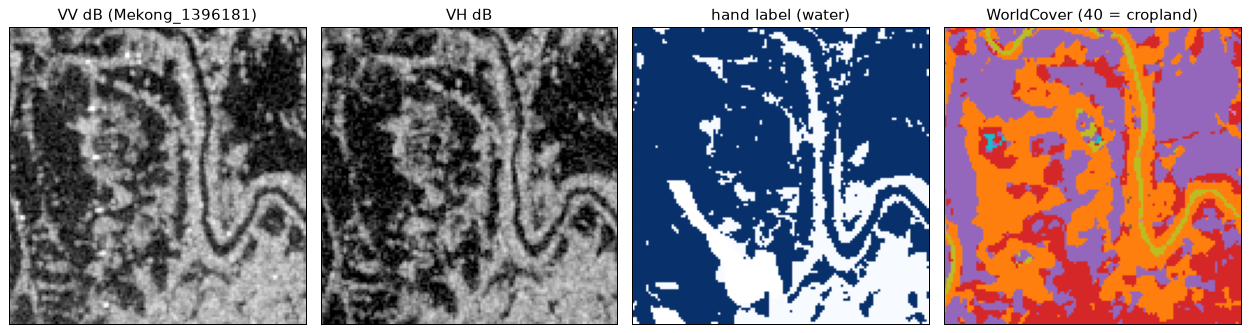

In [3]:
c = next(c for c in chips if c["split"] == "train" and c["y"][c["domain"]].mean() > 0.2)
fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
ax[0].imshow(c["s1_vv"], cmap="gray", vmin=-25, vmax=0); ax[0].set_title(f"VV dB ({c['chip']})")
ax[1].imshow(c["s1_vh"], cmap="gray", vmin=-30, vmax=-5); ax[1].set_title("VH dB")
ax[2].imshow(np.where(c["label"] < 0, np.nan, c["label"]), cmap="Blues"); ax[2].set_title("hand label (water)")
ax[3].imshow(c["landcover"] if c.get("landcover") is not None else np.zeros_like(c["label"]), cmap="tab20", vmin=0, vmax=100)
ax[3].set_title("WorldCover (40 = cropland)")
for a in ax: a.set_xticks([]); a.set_yticks([]); a.grid(False)
plt.tight_layout(); plt.show()

## 2. Predictor 1 (rule stack) and the baseline (Otsu only)

Predictor 1 is copied and adapted from the earlier `sar_water_otsu` v1.1 and `sar_logratio_change` instruments: per chip, 1 km blocks with a clearly bimodal histogram are pooled and a Kittler-Illingworth threshold is fitted on VV and on VH (implausible fits rejected, defaults -17 and -22 dB gamma0). The joint margin min(VV - t_vv, VH - t_vh) becomes a soft score through the earlier 1 dB threshold-error model; on clear optical pixels it is averaged with an MNDWI score; a 3 dB log-ratio drop gates it when a pre-event pair exists (the public sample is single-date, so this branch is idle there). JRC permanent water is set to 0 and left out of every score. The baseline is one global Otsu split of VV per chip, hard 0 or 1.

predictor 1 on 121 chips in 6.0s; components used: ['sar_threshold']; VV threshold fitted (not default) on 20% of chips


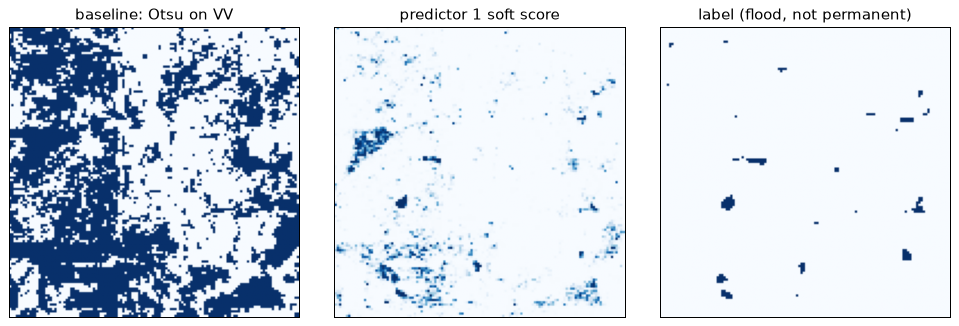

In [4]:
t0 = time.time()
for c in chips:
    p1 = water.predictor1(c)
    c["p1"], c["p1_hard"], c["p1_info"] = p1["p1"], p1["hard"], p1
    c["base"] = water.baseline_otsu(c)["water"]
    c["group"] = water.lc_group(c)
comp = sorted({x for c in chips for x in c["p1_info"]["components"]})
fitted_share = np.mean([c["p1_info"]["fit_vv"]["source"] == "fitted" for c in chips])
print(f"predictor 1 on {len(chips)} chips in {time.time()-t0:.1f}s; components used: {comp}; "
      f"VV threshold fitted (not default) on {fitted_share:.0%} of chips")
fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
ax[0].imshow(c["base"], cmap="Blues"); ax[0].set_title("baseline: Otsu on VV")
ax[1].imshow(c["p1"], cmap="Blues", vmin=0, vmax=1); ax[1].set_title("predictor 1 soft score")
ax[2].imshow(np.where(c["domain"], c["y"], np.nan), cmap="Blues"); ax[2].set_title("label (flood, not permanent)")
for a in ax: a.set_xticks([]); a.set_yticks([]); a.grid(False)
plt.tight_layout(); plt.show()

## 3. Predictor 2: gradient-boosted pixel model

Features per pixel (`water.FEATURES`): VV, VH, VV minus VH, 5 x 5 and 15 x 15 local means, 5 x 5 VV texture, the chip threshold margins of predictor 1, NDWI, MNDWI and NDVI on clear optical pixels (missing otherwise; the model handles missing values), and WorldCover class as a categorical feature. Columns that are all missing in the training sample (the optical indices when layer 1 ships no Sentinel-2) are dropped and listed. Training uses a random sample of 4,000 domain pixels per train chip; three fixed settings are compared by log loss on a pixel sample of the validation events, and the best one is kept. Test is not used.

A small U-Net was the other option in the plan; on CPU and about a hundred chips the boosted pixel model is the cheaper honest choice, and the comparison against the baseline below says whether it earns its place.

In [5]:
def sample_rows(cs, per_chip, seed):
    r = np.random.default_rng(seed)
    X, y, ev, grp, p1 = [], [], [], [], []
    for c in cs:
        F = water.pixel_features(c, c["p1_info"])
        idx = np.flatnonzero(c["domain"].reshape(-1))
        if idx.size > per_chip:
            idx = r.choice(idx, per_chip, replace=False)
        X.append(F[idx]); y.append(c["y"].reshape(-1)[idx]); ev += [c["event"]] * idx.size
        grp.append(c["group"].reshape(-1)[idx]); p1.append(c["p1"].reshape(-1)[idx])
    return np.concatenate(X), np.concatenate(y).astype(int), np.array(ev), np.concatenate(grp), np.concatenate(p1)

by_split = {s: [c for c in chips if c["split"] == s] for s in ("train", "val", "test")}
LC_COL = water.FEATURES.index("lc")
Xtr, ytr, _, _, _ = sample_rows(by_split["train"], 4000, SEED)
Xva, yva, ev_va, g_va, p1_va = sample_rows(by_split["val"], 4000, SEED + 1)
t0 = time.time()
pm = fusion.fit_pixel_model(Xtr, ytr, Xva, yva, lc_col=LC_COL, seed=SEED)
gbm = pm["model"]
print(f"train pixels {len(ytr):,} (flood share {ytr.mean():.3f}); val pixels {len(yva):,} (flood share {yva.mean():.3f}); "
      f"fit {time.time()-t0:.0f}s; chosen config {pm['chosen']}")
print("features used:", [water.FEATURES[j] for j in pm["cols"]], "(all-missing or constant columns dropped)")
pd.DataFrame(pm["table"]).round(4)

train pixels 320,000 (flood share 0.085); val pixels 72,000 (flood share 0.061); fit 30s; chosen config 1
features used: ['vv', 'vh', 'vv_minus_vh', 'vv_m5', 'vh_m5', 'vv_s5', 'vv_m15', 'vh_m15', 'margin', 'vv_rel_t', 'lc'] (all-missing or constant columns dropped)


,config,max_iter,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,val_log_loss
0,0,200,0.10,31,200,1.0,0.1252
1,1,300,0.05,15,500,1.0,0.1238
2,2,150,0.10,63,100,0.0,0.1269


In [6]:
t0 = time.time()
for c in chips:
    F = water.pixel_features(c, c["p1_info"])
    c["p2"] = fusion.predict_pixel_model(gbm, F, LC_COL).reshape(c["s1_vv"].shape)
    c["p2"][~c["domain"]] = 0.0
print(f"predictor 2 maps for all chips in {time.time()-t0:.0f}s")

predictor 2 maps for all chips in 11s


## 4. Fusion with weights per land cover (validation events only)

`logit P = a_g + w_g1 logit(p1) + w_g2 logit(p2)` for each WorldCover group g, L2-regularised logistic regression, fitted on all domain pixels of the validation events (no test). A group with fewer than 500 validation pixels of either class borrows the pooled weights. To get validation scores the fusion has not seen (needed for the calibrator and for an honest validation number), the fusion is also fitted leave-one-validation-event-out. Predictor 3 (an external flood product) has a slot in the fusion but is not available offline, so it is not used here.

In [7]:
def stack(cs, key):
    return np.concatenate([c[key][c["domain"]].reshape(-1) for c in cs])

VA = {k: stack(by_split["val"], k) for k in ("p1", "p2", "y", "group", "base", "p1_hard")}
VA["event"] = np.concatenate([np.full(int(c["domain"].sum()), c["event"]) for c in by_split["val"]])
names = ("p1_rule_stack", "p2_boosted_pixels")
P_va = np.stack([VA["p1"], VA["p2"]], 1)
fus, fused_oof_va = fusion.fit_fusion_crossfit(P_va, VA["y"].astype(int), VA["group"], VA["event"], names, C=1.0, min_class_px=500)
wt = pd.DataFrame({g: {"intercept": w[0], "w_p1": w[1], "w_p2": w[2], "source": fus.source[g],
                       "val_neg": fus.counts[g][0], "val_pos": fus.counts[g][1]} for g, w in fus.weights.items()}).T
print("validation pixels used for fusion:", len(VA["y"]))
wt

validation pixels used for fusion: 264821


,intercept,w_p1,w_p2,source,val_neg,val_pos
_pooled,1.401848,0.16118,0.825029,pooled,248117,16704
bare,1.401848,0.16118,0.825029,pooled (too few val pixels of one class),356,19
built,1.401848,0.16118,0.825029,pooled (too few val pixels of one class),2319,33
cropland,1.65199,0.095663,0.965492,own,57099,9003
open_water,1.401848,0.16118,0.825029,pooled (too few val pixels of one class),28,475
shrub_grass,1.707707,0.190913,0.888054,own,97112,5986
tree,0.335208,0.314361,0.403077,own,91146,1188
wetland,1.401848,0.16118,0.825029,pooled (too few val pixels of one class),57,0


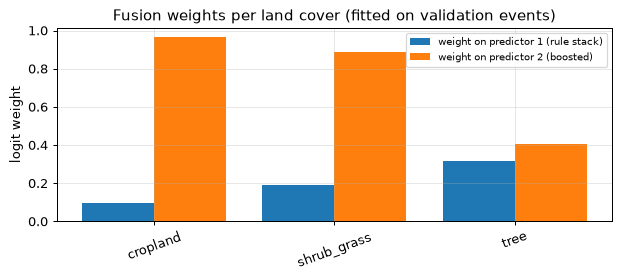

In [8]:
own = wt[wt["source"] == "own"]
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(own))
ax.bar(x - 0.2, own["w_p1"].astype(float), 0.4, label="weight on predictor 1 (rule stack)")
ax.bar(x + 0.2, own["w_p2"].astype(float), 0.4, label="weight on predictor 2 (boosted)")
ax.set_xticks(x, own.index, rotation=20); ax.set_ylabel("logit weight"); ax.legend(fontsize=8)
ax.set_title("Fusion weights per land cover (fitted on validation events)")
plt.tight_layout(); plt.show()

## 5. Calibration (validation only)

Candidates: identity (the fused probability as is), temperature (one parameter on the logit) and isotonic. Each is fitted on the out-of-fold fused validation scores of all but one validation event and scored by ECE (15 equal-width bins) on the held-out event; the lowest mean held-out ECE wins and is refitted on all validation events.

In [9]:
cal_sel = calibrate.choose_by_event(fused_oof_va, VA["y"].astype(int), VA["event"])
cal = cal_sel["calibrator"]
print("held-out-event ECE on validation:", {k: round(v, 4) for k, v in cal_sel["mean_heldout_ece"].items()}, "-> chosen:", cal_sel["chosen"])
pd.DataFrame(cal_sel["per_event"]).round(4)

held-out-event ECE on validation: {'identity': 0.0469, 'temperature': 0.0554, 'isotonic': 0.099} -> chosen: identity


,identity,temperature,isotonic
Ghana,0.0574,0.0728,0.0937
Sri-Lanka,0.0364,0.0379,0.1043


## 6. Paddy mask and P(flooded paddy)

`P(flooded paddy) = P(flooded, not permanent water) x paddy`. The paddy layer is layer 1's `paddy` array when present; otherwise WorldCover 2021 cropland (class 40) is a proxy. WorldCover has no paddy class, so outside rice regions this counts all cropland; the notebook reports calibration both over all land and inside the paddy mask so the effect of the mask is visible.

In [10]:
def apply_layer2(c):
    P = np.stack([c["p1"].reshape(-1), c["p2"].reshape(-1)], 1)
    pf = cal(fus.predict(P, c["group"].reshape(-1))).reshape(c["s1_vv"].shape)
    c["p_flood"] = np.where(c["domain"], pf, 0.0)
    c["paddy"], c["paddy_source"] = water.paddy_mask(c)
    c["p_fp"] = c["p_flood"] * c["paddy"]

for c in chips:
    apply_layer2(c)
print("paddy source:", sorted({c["paddy_source"] for c in chips}))

paddy source: ['WorldCover 2021 cropland (class 40) proxy']


### Validation scores (all models, baseline first)

Validation numbers are optimistic for predictor 2 (its setting was chosen on validation) and for the fused model only through the calibrator choice; the fused row uses the out-of-fold fusion scores. All rows are on the same pixels: domain pixels (labelled, not permanent water) of the validation events.

In [11]:
def table(D, fused_key="fused"):
    rows = {"baseline: Otsu on VV (hard)": D["base"], "predictor 1 hard (earlier rule)": D["p1_hard"],
            "predictor 1 soft": D["p1"], "predictor 2 boosted": D["p2"], "fused (before calibration)": D[fused_key],
            "fused + calibrated": D["cal"]}
    return pd.DataFrame({k: calibrate.scores(v.astype(float), D["y"]) for k, v in rows.items()}).T[
        ["n", "prevalence", "mean_p", "ece", "ece_p_ge_0.05", "brier", "log_loss", "auc", "iou", "f1", "area_ratio_expected"]]

VA["fused"] = fused_oof_va
VA["cal"] = cal(fused_oof_va)
val_table = table(VA)
val_table.round(4)

,n,prevalence,mean_p,ece,ece_p_ge_0.05,brier,log_loss,auc,iou,f1,area_ratio_expected
baseline: Otsu on VV (hard),264821.0,0.0631,0.4483,0.4390,0.9193,0.4390,6.0652,0.5670,0.0762,0.1415,7.1076
predictor 1 hard (earlier rule),264821.0,0.0631,0.0374,0.0337,0.1078,0.0337,0.4659,0.7625,0.4975,0.6644,0.5932
predictor 1 soft,264821.0,0.0631,0.0456,0.0282,0.1340,0.0320,0.1995,0.9320,0.4908,0.6585,0.7230
predictor 2 boosted,264821.0,0.0631,0.0384,0.0247,0.1904,0.0307,0.1145,0.9538,0.4109,0.5825,0.6088
fused (before calibration),264821.0,0.0631,0.0725,0.0212,0.0799,0.0403,0.1529,0.9222,0.3559,0.5250,1.1489
fused + calibrated,264821.0,0.0631,0.0725,0.0212,0.0799,0.0403,0.1529,0.9222,0.3559,0.5250,1.1489


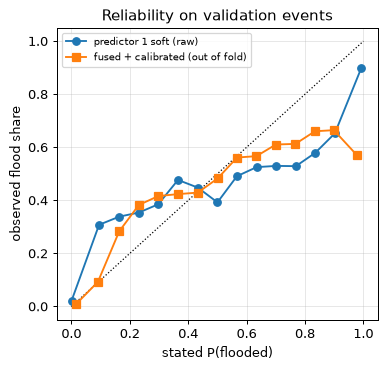

In [12]:
r = calibrate.reliability(VA["cal"], VA["y"])
r0 = calibrate.reliability(VA["p1"], VA["y"])
fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.plot(r0["conf"], r0["freq"], "o-", label="predictor 1 soft (raw)")
ax.plot(r["conf"], r["freq"], "s-", label="fused + calibrated (out of fold)")
ax.set_xlabel("stated P(flooded)"); ax.set_ylabel("observed flood share"); ax.legend(fontsize=8)
ax.set_title("Reliability on validation events")
plt.tight_layout(); plt.show()

## 7. TEST (touched once)

Everything above was fitted on train and validation events only. This cell scores the test events (India, Bolivia under the default split) once, and its numbers are reported as they come out, including where they are worse than validation. Nothing is refitted after it.

In [13]:
# ===================== TEST CELL: run once, nothing is fitted below this line =====================
TE = {k: stack(by_split["test"], k) for k in ("p1", "p2", "y", "group", "base", "p1_hard", "p_flood")}
TE["event"] = np.concatenate([np.full(int(c["domain"].sum()), c["event"]) for c in by_split["test"]])
TE["fused"] = fus.predict(np.stack([TE["p1"], TE["p2"]], 1), TE["group"])
TE["cal"] = TE["p_flood"]
test_table = table(TE)
gap = pd.DataFrame({"val": val_table["ece"], "test": test_table["ece"]})
gap["test_minus_val"] = gap["test"] - gap["val"]
gap_iou = pd.DataFrame({"val": val_table["iou"], "test": test_table["iou"]}); gap_iou["test_minus_val"] = gap_iou["test"] - gap_iou["val"]
print("TEST, all land (domain pixels of test events)")
display(test_table.round(4))
print("ECE gap (test minus val)"); display(gap.round(4))
print("IoU gap (test minus val)"); display(gap_iou.round(4))

TEST, all land (domain pixels of test events)


,n,prevalence,mean_p,ece,ece_p_ge_0.05,brier,log_loss,auc,iou,f1,area_ratio_expected
baseline: Otsu on VV (hard),323795.0,0.1187,0.3779,0.3380,0.7901,0.3380,4.6691,0.6648,0.1901,0.3194,3.1841
predictor 1 hard (earlier rule),323795.0,0.1187,0.0632,0.0873,0.2517,0.0873,1.2063,0.6901,0.3512,0.5198,0.5322
predictor 1 soft,323795.0,0.1187,0.0757,0.0736,0.2197,0.0783,0.5448,0.8992,0.3802,0.5509,0.6379
predictor 2 boosted,323795.0,0.1187,0.0596,0.0606,0.2082,0.0727,0.2650,0.9278,0.2929,0.4530,0.5026
fused (before calibration),323795.0,0.1187,0.0997,0.0387,0.1280,0.0627,0.2182,0.9339,0.4193,0.5909,0.8399
fused + calibrated,323795.0,0.1187,0.0997,0.0387,0.1280,0.0627,0.2182,0.9339,0.4193,0.5909,0.8399


ECE gap (test minus val)


,val,test,test_minus_val
baseline: Otsu on VV (hard),0.4390,0.3380,-0.1011
predictor 1 hard (earlier rule),0.0337,0.0873,0.0536
predictor 1 soft,0.0282,0.0736,0.0454
predictor 2 boosted,0.0247,0.0606,0.0360
fused (before calibration),0.0212,0.0387,0.0175
fused + calibrated,0.0212,0.0387,0.0175


IoU gap (test minus val)


,val,test,test_minus_val
baseline: Otsu on VV (hard),0.0762,0.1901,0.1139
predictor 1 hard (earlier rule),0.4975,0.3512,-0.1463
predictor 1 soft,0.4908,0.3802,-0.1106
predictor 2 boosted,0.4109,0.2929,-0.1181
fused (before calibration),0.3559,0.4193,0.0634
fused + calibrated,0.3559,0.4193,0.0634


In [14]:
# Inside the paddy mask, and per test event
PADDY_TE = np.concatenate([c["paddy"][c["domain"]].reshape(-1) for c in by_split["test"]]) >= 0.5
TEp = {k: v[PADDY_TE] for k, v in TE.items()}
test_paddy_table = table(TEp)
print(f"TEST inside the paddy mask ({PADDY_TE.sum():,} pixels, {PADDY_TE.mean():.0%} of test domain)")
display(test_paddy_table.round(4))
per_event = pd.DataFrame({e: {"pixels": int((TE["event"] == e).sum()),
                              "ece_baseline": calibrate.ece(TE["base"][TE["event"] == e].astype(float), TE["y"][TE["event"] == e]),
                              "ece_calibrated": calibrate.ece(TE["cal"][TE["event"] == e], TE["y"][TE["event"] == e]),
                              "iou_baseline": calibrate.scores(TE["base"][TE["event"] == e].astype(float), TE["y"][TE["event"] == e])["iou"],
                              "iou_calibrated": calibrate.scores(TE["cal"][TE["event"] == e], TE["y"][TE["event"] == e])["iou"]}
                          for e in np.unique(TE["event"])}).T
display(per_event.round(4))

TEST inside the paddy mask (86,774 pixels, 27% of test domain)


,n,prevalence,mean_p,ece,ece_p_ge_0.05,brier,log_loss,auc,iou,f1,area_ratio_expected
baseline: Otsu on VV (hard),86774.0,0.2465,0.4613,0.4018,0.6683,0.4018,5.5506,0.6058,0.2758,0.4324,1.8713
predictor 1 hard (earlier rule),86774.0,0.2465,0.0595,0.1940,0.0588,0.1940,2.6797,0.6113,0.2242,0.3662,0.2416
predictor 1 soft,86774.0,0.2465,0.0861,0.1695,0.2279,0.1727,1.2530,0.8271,0.2719,0.4276,0.3492
predictor 2 boosted,86774.0,0.2465,0.0732,0.1733,0.3787,0.1697,0.6081,0.8643,0.1759,0.2992,0.2971
fused (before calibration),86774.0,0.2465,0.1473,0.0992,0.1623,0.1292,0.4287,0.8694,0.3412,0.5088,0.5977
fused + calibrated,86774.0,0.2465,0.1473,0.0992,0.1623,0.1292,0.4287,0.8694,0.3412,0.5088,0.5977


,pixels,ece_baseline,ece_calibrated,iou_baseline,iou_calibrated
Bolivia,141350.0,0.3076,0.0304,0.1714,0.5273
India,182445.0,0.3615,0.0522,0.2020,0.3563


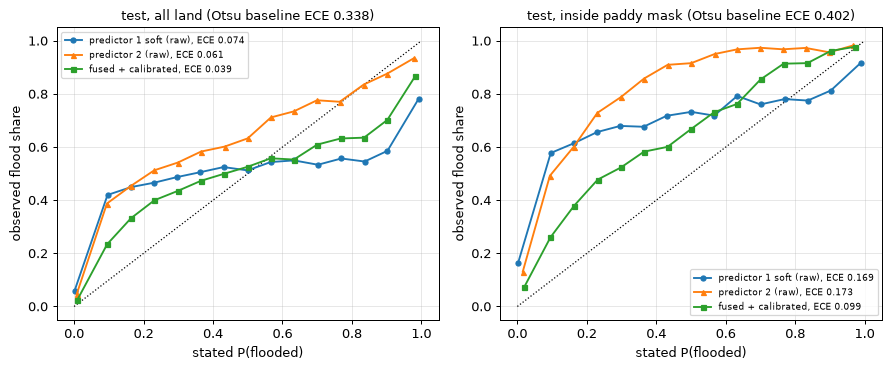

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for D, a, ttl in ((TE, ax[0], "test, all land"), (TEp, ax[1], "test, inside paddy mask")):
    a.plot([0, 1], [0, 1], "k:", lw=1)
    for key, lab, m in (("p1", "predictor 1 soft (raw)", "o-"), ("p2", "predictor 2 (raw)", "^-"), ("cal", "fused + calibrated", "s-")):
        r = calibrate.reliability(D[key], D["y"])
        a.plot(r["conf"], r["freq"], m, ms=4, label=f"{lab}, ECE {calibrate.ece(D[key], D['y']):.3f}")
    b = calibrate.scores(D["base"].astype(float), D["y"])
    a.set_title(f"{ttl} (Otsu baseline ECE {b['ece']:.3f})", fontsize=10)
    a.set_xlabel("stated P(flooded)"); a.set_ylabel("observed flood share"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [16]:
# Chip-level area check on test: expected flooded-paddy area (sum of probabilities) vs hand label, and baseline
px_km2 = 0.02 * 0.02
rows = []
for c in by_split["test"]:
    m = c["domain"] & (c["paddy"] >= 0.5)
    rows.append({"chip": c["chip"], "event": c["event"], "label_km2": (c["y"] & m).sum() * px_km2,
                 "calibrated_expected_km2": c["p_fp"][m].sum() * px_km2, "baseline_km2": (c["base"] & m).sum() * px_km2})
area = pd.DataFrame(rows)
tot = area[["label_km2", "calibrated_expected_km2", "baseline_km2"]].sum()
print("test totals inside paddy mask (km2):", tot.round(3).to_dict())
mae = {"calibrated": float((area.calibrated_expected_km2 - area.label_km2).abs().mean()),
       "baseline": float((area.baseline_km2 - area.label_km2).abs().mean())}
print("mean absolute chip error (km2):", {k: round(v, 4) for k, v in mae.items()})

test totals inside paddy mask (km2): {'label_km2': 8.556, 'calibrated_expected_km2': 5.114, 'baseline_km2': 16.011}
mean absolute chip error (km2): {'calibrated': 0.1595, 'baseline': 0.4925}


## 8. Submergence duration (semi-synthetic) and crop survival

**Label: semi-synthetic.** The public chips have one SAR date. The flood footprint at that pass is real (hand label for truth, the calibrated map's own call for the observation), but the flood onset, the duration and the other passes are simulated: 12-day revisit, 2 passes before and 4 after, flood onset 0 to 6 days before the observed pass, log-normal durations with an event median drawn between 4 and 14 days and longer durations for darker (deeper) pixels. The other passes are observed with the map's validation sensitivity and specificity at 0.5.

From each pixel's wet/dry passes we get an interval [lo, hi] for its duration (right-censored when no dry pass follows). The Turnbull NPMLE fits the duration distribution on train events; for a pixel, `P(submerged >= d) = P(flooded) x P(D >= d | interval)`. The baseline is the naive count `wet passes x revisit`. Both are scored on the test events against the simulated truth.

In [17]:
thr = VA["cal"] >= 0.5
sens = float(thr[VA["y"] == 1].mean()); spec = float((~thr)[VA["y"] == 0].mean())
cfg = duration.SimConfig(seed=SEED)
drng = np.random.default_rng(SEED + 7)
sim = {}
for split in ("train", "test"):
    for ev in sorted({c["event"] for c in by_split[split]}):
        cs = [c for c in by_split[split] if c["event"] == ev]
        offs, o = {}, 0
        for c in cs:
            offs[c["chip"]] = (o, int(c["domain"].sum())); o += offs[c["chip"]][1]
        wet0 = np.concatenate([(c["y"] & c["domain"])[c["domain"]] for c in cs])
        pf = np.concatenate([c["p_flood"][c["domain"]] for c in cs])
        vv = np.concatenate([c["s1_vv"][c["domain"]] for c in cs]).astype(float)
        s = duration.simulate_event(wet0, pf >= 0.5, vv, sens, spec, cfg, drng)
        lo, hi, anyw = duration.intervals_from_obs(s["obs"], s["times"])
        lo = np.where(anyw, lo, 0.0); hi = np.where(anyw, hi, 2 * cfg.revisit_days)
        sim[ev] = {**s, "offsets": offs, "lo": lo, "hi": hi, "p_flood": pf, "split": split, "naive": duration.naive_duration(s["obs"], cfg.revisit_days)}
fit_lo = np.concatenate([v["lo"][v["obs"][cfg.passes_before]] for v in sim.values() if v["split"] == "train"])
fit_hi = np.concatenate([v["hi"][v["obs"][cfg.passes_before]] for v in sim.values() if v["split"] == "train"])
dm = duration.fit_turnbull(fit_lo, fit_hi)
print(f"map sensitivity {sens:.3f}, specificity {spec:.3f} (validation); Turnbull fitted on {fit_lo.size:,} train pixels")

map sensitivity 0.468, specificity 0.979 (validation); Turnbull fitted on 105,286 train pixels


In [18]:
dur_rows = []
for d in duration.DUR_DAYS:
    P, Y, N = [], [], []
    for ev, v in sim.items():
        if v["split"] != "test":
            continue
        P.append(v["p_flood"] * dm.p_ge(d, v["lo"], v["hi"])); Y.append(v["D"] >= d); N.append((v["naive"] >= d).astype(float))
    P, Y, N = np.concatenate(P), np.concatenate(Y), np.concatenate(N)
    s1, s0 = calibrate.scores(P, Y), calibrate.scores(N, Y)
    dur_rows.append({"d_days": d, "true_share": Y.mean(), "turnbull_ece": s1["ece"], "turnbull_brier": s1["brier"], "turnbull_auc": s1["auc"],
                     "naive_ece": s0["ece"], "naive_brier": s0["brier"]})
dur_table = pd.DataFrame(dur_rows)
print("SEMI-SYNTHETIC duration check on test events")
dur_table.round(4)

SEMI-SYNTHETIC duration check on test events


,d_days,true_share,turnbull_ece,turnbull_brier,turnbull_auc,naive_ece,naive_brier
0,3,0.1180,0.0383,0.0625,0.9343,0.1735,0.1735
1,7,0.0925,0.0311,0.0559,0.9366,0.1692,0.1692
2,10,0.0654,0.0351,0.0537,0.9358,0.1690,0.1690
3,14,0.0379,0.0466,0.0442,0.9364,0.0376,0.0376


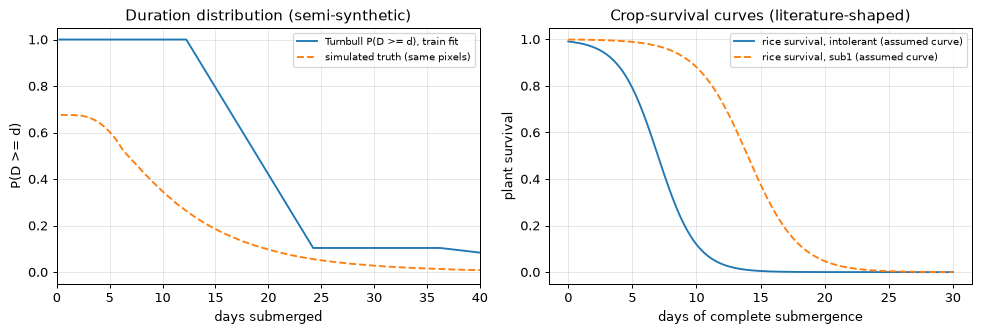

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
F = np.cumsum(dm.pmf)
ax[0].plot(dm.grid, 1 - F + dm.pmf, label="Turnbull P(D >= d), train fit")
dtrue = np.concatenate([v["D"][v["obs"][cfg.passes_before]] for v in sim.values() if v["split"] == "train"])
ax[0].plot(np.sort(dtrue), 1 - np.arange(dtrue.size) / dtrue.size, "--", label="simulated truth (same pixels)")
ax[0].set_xlim(0, 40); ax[0].set_xlabel("days submerged"); ax[0].set_ylabel("P(D >= d)"); ax[0].legend(fontsize=8)
ax[0].set_title("Duration distribution (semi-synthetic)")
dd = np.linspace(0, 30, 200)
for var, ls in (("intolerant", "-"), ("sub1", "--")):
    ax[1].plot(dd, duration.crop_survival(dd, var), ls, label=f"rice survival, {var} (assumed curve)")
ax[1].set_xlabel("days of complete submergence"); ax[1].set_ylabel("plant survival"); ax[1].legend(fontsize=8)
ax[1].set_title("Crop-survival curves (literature-shaped)")
plt.tight_layout(); plt.show()

## 9. Write layer 2 artifacts

Per chip `maps/<chip>.npz` (uint8 scaled 0 to 250 = probability 0 to 1, 255 = no call): `p_flooded_paddy`, `p_flooded`, `paddy`, and the semi-synthetic `p_sub_ge_{3,7,10,14}d` and `crop_loss_intolerant`; plus `label` and `domain` passed through so layer 3 can simulate field checks. `chips.parquet` has one row per chip; `models.json` the fusion weights, calibrator and pixel-model choice; `metrics.json` every table above; `MANIFEST.json` the schema, shapes, seed and source hashes.

In [20]:
def q8(p, dom):
    out = np.full(p.shape, 255, "uint8")
    out[dom] = np.round(np.clip(p[dom], 0, 1) * 250).astype("uint8")
    return out

maps = L2 / "maps"; maps.mkdir(exist_ok=True)
for f in maps.glob("*.npz"):
    f.unlink()
loss_f = lambda g: 1 - duration.crop_survival(g, "intolerant")
rows = []
for c in chips:
    dom = c["domain"]
    v = sim.get(c["event"])
    out = {"p_flooded_paddy": q8(c["p_fp"], dom), "p_flooded": q8(c["p_flood"], dom), "paddy": q8(c["paddy"], dom),
           "label": c["label"], "domain": dom.astype("uint8"), "chip": c["chip"], "event": c["event"], "split": c["split"]}
    # duration for every chip: intervals from a fresh simulation for events not simulated above
    if v is None:
        wet0 = (c["y"] & dom)[dom]
        v1 = duration.simulate_event(wet0, c["p_flood"][dom] >= 0.5, c["s1_vv"][dom].astype(float), sens, spec, cfg,
                                     np.random.default_rng(zlib.crc32(str(c["chip"]).encode())))
        lo, hi, anyw = duration.intervals_from_obs(v1["obs"], v1["times"])
        lo = np.where(anyw, lo, 0.0); hi = np.where(anyw, hi, 2 * cfg.revisit_days)
    else:
        o, n = v["offsets"][c["chip"]]
        lo, hi = v["lo"][o:o + n], v["hi"][o:o + n]
    for d in duration.DUR_DAYS:
        m = np.zeros(dom.shape); m[dom] = c["p_fp"][dom] * dm.p_ge(d, lo, hi)
        out[f"p_sub_ge_{d}d"] = q8(m, dom)
    m = np.zeros(dom.shape); m[dom] = c["p_fp"][dom] * dm.expected(loss_f, lo, hi)
    out["crop_loss_intolerant"] = q8(m, dom)
    np.savez_compressed(maps / f"{c['chip']}.npz", **out)
    bounds = c.get("bounds")
    rows.append({"chip": c["chip"], "event": c["event"], "split": c["split"], "h": dom.shape[0], "w": dom.shape[1],
                 "domain_px": int(dom.sum()), "paddy_px": int((c["paddy"][dom] >= 0.5).sum()),
                 "expected_flooded_paddy_px": float(c["p_fp"][dom].sum()),
                 "label_flooded_paddy_px": int((c["y"] & dom & (c["paddy"] >= 0.5)).sum()),
                 "baseline_flooded_paddy_px": int((c["base"] & dom & (c["paddy"] >= 0.5)).sum()),
                 "bounds": None if bounds is None else [float(b) for b in np.ravel(bounds)]})
chip_df = pd.DataFrame(rows)
chip_df.to_parquet(L2 / "chips.parquet", index=False)
chip_df.drop(columns=["bounds"]).to_csv(L2 / "chips.csv", index=False)
print(len(rows), "chip maps written;", f"{sum(f.stat().st_size for f in maps.glob('*.npz'))/1e6:.1f} MB")
chip_df.groupby("split")[["domain_px", "paddy_px", "expected_flooded_paddy_px", "label_flooded_paddy_px", "baseline_flooded_paddy_px"]].sum()

121 chip maps written; 4.1 MB


,domain_px,paddy_px,expected_flooded_paddy_px,label_flooded_paddy_px,baseline_flooded_paddy_px
split,,,,,
test,323795,86774,12785.685277,21390,40027
train,1198007,326288,59868.777185,33509,136553
val,264821,66102,9004.312955,9003,35124


In [21]:
def tdict(df):
    return json.loads(df.round(6).to_json(orient="index"))

models = {"fusion": fus.spec(), "calibrator": cal.spec(), "calibrator_selection": {k: v for k, v in cal_sel.items() if k != "calibrator"},
          "pixel_model": {"type": "sklearn HistGradientBoostingClassifier", "features": list(water.FEATURES), "chosen_config": pm["chosen"],
                          "selection_table": pm["table"], "features_used": [water.FEATURES[j] for j in pm["cols"]], "train_pixels": int(len(ytr)), "val_pixels": int(len(yva))},
          "predictor1": {"components_used": comp, "vv_threshold_fitted_share": float(fitted_share),
                         "rules": "split-based Kittler-Illingworth on VV and VH (earlier sar_water_otsu v1.1), 1 dB threshold error, MNDWI on clear S2, 3 dB log-ratio gate when a pre pair exists"},
          "duration": {"semi_synthetic": True, "sim": cfg.__dict__, "map_sensitivity": sens, "map_specificity": spec,
                       "turnbull_grid_days": dm.grid.tolist(), "turnbull_pmf": dm.pmf.tolist(), "survival": duration.SURVIVAL}}
metrics = {"val": tdict(val_table), "test": tdict(test_table), "test_paddy": tdict(test_paddy_table), "ece_gap": tdict(gap),
           "iou_gap": tdict(gap_iou), "test_per_event": tdict(per_event), "test_area_km2": {k: float(v) for k, v in tot.items()},
           "test_chip_mae_km2": mae, "duration_test_semi_synthetic": json.loads(dur_table.round(6).to_json(orient="records"))}
(L2 / "models.json").write_text(water.dumps(models))
(L2 / "metrics.json").write_text(water.dumps(metrics))

src_dir = L1 if source == "layer1" else FALLBACK
manifest = {
    "layer": 2, "notebook": "02_mapping.ipynb", "seed": SEED, "created": time.strftime("%Y-%m-%d %H:%M"),
    "input": {"source": source, "dir": str(src_dir.relative_to(NB)), "fetch": fetch_info, "split_source": split_source,
              "splits": {s: sorted({c["event"] for c in by_split[s]}) for s in by_split},
              "chips_per_split": {s: len(v) for s, v in by_split.items()},
              "assumed_layer1_chip_schema": {
                  "file": "artifacts/layer1/**/*.npz, one chip per file, or stacked with a leading chip axis and a 'chip' array",
                  "required": {"s1_vv": "float (H,W) post-event VV dB gamma0", "s1_vh": "float (H,W) post-event VH dB",
                               "label": "int (H,W) 1 water, 0 not water, -1 unlabelled", "event": "str"},
                  "optional": {"chip": "str", "split": "train|val|test, constant per event", "s2": "float (6,H,W) reflectance B2 B3 B4 B8 B11 B12",
                               "perm_water": "uint8 (H,W) JRC permanent water", "landcover": "uint8 (H,W) ESA WorldCover 2021 codes",
                               "paddy": "float or uint8 (H,W) paddy mask or probability", "s1_pre_vv": "float (H,W)", "s1_pre_vh": "float (H,W)"}},
              "source_hashes": {f.name: water.file_sha(f) for f in sorted(src_dir.rglob("*.npz"))[:400]}},
    "outputs": {
        "maps/<chip>.npz": {"encoding": "uint8, value/250 = probability, 255 = no call (outside domain)",
                            "arrays": {"p_flooded_paddy": "calibrated P(flooded paddy)", "p_flooded": "calibrated P(flooded, not permanent water)",
                                       "paddy": "paddy mask or probability used", "p_sub_ge_{3,7,10,14}d": "SEMI-SYNTHETIC P(submerged >= d days) x paddy",
                                       "crop_loss_intolerant": "SEMI-SYNTHETIC expected plant loss share, intolerant rice x P(flooded paddy)",
                                       "label": "int8 hand label passed through (1 water, 0 not, -1 unlabelled)",
                                       "domain": "uint8 1 where a call is made (labelled, not permanent water)",
                                       "chip": "str", "event": "str", "split": "str"},
                            "shape": list(chips[0]["s1_vv"].shape), "pixel_m": 20},
        "chips.parquet": "one row per chip: split, pixel counts, expected / label / baseline flooded-paddy pixels, bounds (lon/lat) if known",
        "chips.csv": "same without bounds", "models.json": "fusion weights, calibrator, pixel-model selection, duration model",
        "metrics.json": "val and test tables, gaps, per-event test, area check, semi-synthetic duration check"},
    "paddy_source": sorted({c["paddy_source"] for c in chips}),
    "semi_synthetic": ["p_sub_ge_*", "crop_loss_intolerant", "duration"],
    "output_hashes": {f.name: water.file_sha(f) for f in [L2 / "chips.parquet", L2 / "models.json", L2 / "metrics.json"]},
}
(L2 / "MANIFEST.json").write_text(water.dumps(manifest))
print("wrote", sorted(p.name for p in L2.iterdir()))

wrote ['MANIFEST.json', 'chips.csv', 'chips.parquet', 'maps', 'metrics.json', 'models.json']


## Results in one place

The cell below prints the headline comparison straight from the tables above (test numbers were computed once, in section 7).

In [22]:
key = ["baseline: Otsu on VV (hard)", "predictor 1 soft", "predictor 2 boosted", "fused + calibrated"]
head = pd.DataFrame({"val_ece": val_table.loc[key, "ece"], "test_ece": test_table.loc[key, "ece"],
                     "test_ece_paddy": test_paddy_table.loc[key, "ece"], "test_ece_p_ge_0.05": test_table.loc[key, "ece_p_ge_0.05"],
                     "val_iou": val_table.loc[key, "iou"],
                     "test_iou": test_table.loc[key, "iou"], "test_brier": test_table.loc[key, "brier"]})
beats = test_table.loc["fused + calibrated", "brier"] < test_table.loc["baseline: Otsu on VV (hard)", "brier"]
beats_iou = test_table.loc["fused + calibrated", "iou"] > test_table.loc["baseline: Otsu on VV (hard)", "iou"]
fusion_helps = test_table.loc["fused + calibrated", "brier"] < test_table.loc["predictor 2 boosted", "brier"]
print(f"fused + calibrated beats the Otsu baseline on test Brier: {beats}; on test IoU: {beats_iou}")
print(f"fusion beats predictor 2 alone on test Brier: {fusion_helps} "
      f"({test_table.loc['fused + calibrated', 'brier']:.4f} vs {test_table.loc['predictor 2 boosted', 'brier']:.4f})")
head.round(4)

fused + calibrated beats the Otsu baseline on test Brier: True; on test IoU: True
fusion beats predictor 2 alone on test Brier: True (0.0627 vs 0.0727)


,val_ece,test_ece,test_ece_paddy,test_ece_p_ge_0.05,val_iou,test_iou,test_brier
baseline: Otsu on VV (hard),0.4390,0.3380,0.4018,0.7901,0.0762,0.1901,0.3380
predictor 1 soft,0.0282,0.0736,0.1695,0.2197,0.4908,0.3802,0.0783
predictor 2 boosted,0.0247,0.0606,0.1733,0.2082,0.4109,0.2929,0.0727
fused + calibrated,0.0212,0.0387,0.0992,0.1280,0.3559,0.4193,0.0627


## Assertions

Bounds stated before the test cell was run: the calibrated map's test ECE (all land) must be at most 0.10, its test Brier must not exceed the Otsu baseline's, every output probability must lie in [0, 1], and the MANIFEST must list every chip map.

In [23]:
e_test = float(test_table.loc["fused + calibrated", "ece"])
assert e_test <= 0.10, f"test ECE {e_test:.3f} above the 0.10 bound"
assert test_table.loc["fused + calibrated", "brier"] <= test_table.loc["baseline: Otsu on VV (hard)", "brier"], "calibrated map worse than Otsu baseline on Brier"
assert all(0 <= c["p_fp"].min() and c["p_fp"].max() <= 1 for c in chips)
assert len(list((L2 / "maps").glob("*.npz"))) == len(chips) == len(chip_df)
print(f"OK: test ECE {e_test:.4f} <= 0.10; Brier {test_table.loc['fused + calibrated', 'brier']:.4f} vs baseline "
      f"{test_table.loc['baseline: Otsu on VV (hard)', 'brier']:.4f}")

OK: test ECE 0.0387 <= 0.10; Brier 0.0627 vs baseline 0.3380
